# Milestone 3 — Predicting Google Play install tiers: classification and regression
Twelve classifiers and thirteen regressors are tuned, trained and compared; all results appear in this notebook, ready for the ACM report.

* **Split:** one 80/20 split per task, stratified on the 4 install tiers (Low ≤10k · Moderate ≤100k · High ≤1M · Very High >1M). Full-data models are scored on the whole held-out 20% (~462k apps); KNN and the RBF models, too slow for that, are scored on a stratified 50k subset of it. All models are also scored on that same 50k subset (`F1 (common 50k)`), which is the fair ranking column.
* **Data size:** all 1.85M training rows, except KNN (200k) and RBF SVM/SVR (50k), whose memory grows quadratically.
* **Tuning:** 3-fold grid search on a stratified 150k training sample (macro-F1 for classification, RMSE for regression); the best setting is refit on the full training set.
* **Metrics:** regression predictions are binned into the same 4 tiers, so accuracy and macro precision / recall / F1 are comparable across both tasks; classifiers use balanced class weights.

**1 · Setup and data.** Mounts Drive and loads both CSVs as `float32` (leakage columns dropped).

In [ ]:
import os, gc, time, inspect, warnings, hashlib, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
from IPython.display import display
from sklearn import metrics as skm
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression, Perceptron, LinearRegression, Ridge, Lasso, BayesianRidge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import LinearSVC, SVC, LinearSVR, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor, AdaBoostClassifier, AdaBoostRegressor,
                              BaggingClassifier, BaggingRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier, MLPRegressor

warnings.filterwarnings('ignore', category=ConvergenceWarning)
drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/ML-Datasets'
CLF_PATH, REG_PATH = (os.path.join(DATA_DIR, f) for f in ('googleplaystore_classification.csv', 'google_playstore_cleaned.csv'))

SEED, QUICK, QUICK_ROWS = 42, False, 100_000          # QUICK=True: fast dry run on a random 100k rows
TUNE_N, TUNE_CV, KNN_N, SVM_N, SVM_TUNE_N, EVAL_N = 150_000, 3, 200_000, 50_000, 10_000, 50_000
CKPT = os.path.join(DATA_DIR, 'checkpoints_quick' if QUICK else 'checkpoints'); os.makedirs(CKPT, exist_ok=True)
CLASS_NAMES = ['Low', 'Moderate', 'High', 'Very High']
EDGES = np.log1p([1e4, 1e5, 1e6]) + 1e-6              # tier cut points in log(1 + installs) space
LEAK = ['Maximum Installs', 'Minimum Installs', 'Installs', 'Rating Count']
plt.rcParams.update({'figure.dpi': 130, 'savefig.bbox': 'tight'})

def load(path, drop, target, ty):
    cols = [c for c in pd.read_csv(path, nrows=0).columns if c not in drop + [target]]
    df = pd.read_csv(path, usecols=cols + [target], dtype={**dict.fromkeys(cols, np.float32), target: ty})
    return cols, df[cols].to_numpy(np.float32), df[target]

cols_c, Xc, yc = load(CLF_PATH, LEAK + ['Log_Max_Installs'], 'Installs_Class', str)
cols_r, Xr, yr = load(REG_PATH, LEAK, 'Log_Max_Installs', np.float32)
yc, yr = yc.map({n: i for i, n in enumerate(CLASS_NAMES)}).to_numpy(np.int8), yr.to_numpy(np.float32)
print(f'classification {Xc.shape} | regression {Xr.shape}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
classification (2312944, 60) | regression (2312944, 60)


**2 · Split and subsamples.** Both tasks get a tier-stratified split, `Size_MB` standardised with training statistics, and fixed stratified subsamples reused by every model.

In [ ]:
def sub(s, n):
    return np.arange(len(s)) if n >= len(s) else np.sort(train_test_split(np.arange(len(s)), train_size=n, stratify=s, random_state=SEED)[0])

def prep(task, X, y, cols):
    if QUICK:
        k = np.random.default_rng(SEED).choice(len(y), min(QUICK_ROWS, len(y)), replace=False); X, y = X[k], y[k]
    strat = y if task == 'clf' else np.digitize(y, EDGES)
    tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=strat, random_state=SEED)
    if 'Size_MB' in cols:
        j = cols.index('Size_MB'); X[:, j] = (X[:, j] - X[tr, j].mean()) / X[tr, j].std()
    ev = sub(strat[te], EVAL_N)
    return dict(Xtr=X[tr], ytr=y[tr], Str=strat[tr], Xte=X[te], yte=y[te], Xev=X[te][ev], yev=y[te][ev], ev=ev)

D = {'clf': prep('clf', Xc, yc, cols_c), 'reg': prep('reg', Xr, yr, cols_r)}
del Xc, Xr; gc.collect()
for t, d in D.items(): print(f"{t}: train {d['Xtr'].shape[0]:,} | full test {d['Xte'].shape[0]:,} | common evaluation subset {d['Xev'].shape[0]:,}")

clf: train 1,850,355 | full test 462,589 | common evaluation subset 50,000
reg: train 1,850,355 | full test 462,589 | common evaluation subset 50,000


**3 · Helpers.** `run()` tunes (if a grid is given), fits the best setting, scores it (full test set, or the 50k subset for KNN/RBF) and checkpoints the result to Drive (a model is skipped on rerun unless its code changed); `report()` shows the table, bar chart, confusion matrix and per-tier scores.

In [ ]:
tier = lambda task, v: v if task == 'clf' else np.digitize(v, EDGES)
RESULTS, TUNING, PRED = [], [], {}
S = lambda name, est, grid=None, mode='full', bal=False: (name, est, grid, mode, bal)

def metrics(task, yt, p):
    r = {'R2': skm.r2_score(yt, p), 'RMSE': np.sqrt(skm.mean_squared_error(yt, p)), 'MAE': skm.mean_absolute_error(yt, p)} if task == 'reg' else {}
    t, q = tier(task, yt), tier(task, p)
    P, R, F, _ = skm.precision_recall_fscore_support(t, q, average='macro', zero_division=0)
    return r | {'Accuracy': skm.accuracy_score(t, q), 'Precision': P, 'Recall': R, 'F1': F}

def run(task, name, est, grid=None, mode='full', bal=False):
    if (task, name) in PRED: return
    d, clf = D[task], task == 'clf'
    key = hashlib.md5(repr(('v2', task, name, est, grid, mode, bal, QUICK)).encode()).hexdigest()
    ck = os.path.join(CKPT, f"{task}_{name.replace(' ', '_').replace('(', '').replace(')', '')}.pkl")
    if os.path.exists(ck):
        saved = pickle.load(open(ck, 'rb'))
        if saved['key'] == key:
            TUNING.append(saved['tuning']); RESULTS.append(saved['result']); PRED[(task, name)] = saved['pred']
            print(f'{name:20s} restored from checkpoint'); return
    tr = slice(None) if mode == 'full' else sub(d['Str'], KNN_N if mode == 'knn' else SVM_N)
    tuned = {}
    if grid:
        tp = sub(d['Str'], SVM_TUNE_N if mode == 'svm' else TUNE_N)
        cv = list(StratifiedKFold(TUNE_CV, shuffle=True, random_state=SEED).split(tp, d['Str'][tp]))
        gs = GridSearchCV(est, grid, scoring='f1_macro' if clf else 'neg_root_mean_squared_error', cv=cv, n_jobs=-1, refit=False)
        gs.fit(d['Xtr'][tp], d['ytr'][tp])
        est, tuned = clone(est).set_params(**gs.best_params_), gs.best_params_
        cv_score = {'CV macro-F1' if clf else 'CV RMSE': abs(gs.best_score_)}
    trow = {'Task': task, 'Model': name, 'Selected hyperparameters': ', '.join(f'{k}={v}' for k, v in tuned.items()) or 'fixed (not tuned)', **(cv_score if grid else {})}
    kw = {'sample_weight': compute_sample_weight('balanced', d['ytr'][tr])} if bal else {}
    t0 = time.perf_counter(); m = clone(est).fit(d['Xtr'][tr], d['ytr'][tr], **kw); fit_s = time.perf_counter() - t0
    full = mode == 'full'
    p = m.predict(d['Xte'] if full else d['Xev'])
    yt = d['yte'] if full else d['yev']
    r = {'Task': task, 'Model': name, 'Train rows': d['ytr'][tr].size, 'Fit (s)': fit_s, 'Scored on': 'full test' if full else '50k subset', **metrics(task, yt, p),
         'F1 (common 50k)': metrics(task, d['yev'], p[d['ev']] if full else p)['F1']}
    TUNING.append(trow); RESULTS.append(r); PRED[(task, name)] = p
    pickle.dump({'key': key, 'tuning': trow, 'result': r, 'pred': p}, open(ck, 'wb'))
    print(f"{name:20s} F1={r['F1']:.4f}  Acc={r['Accuracy']:.4f}  Prec={r['Precision']:.4f}  Rec={r['Recall']:.4f}  ({fit_s:.0f}s)")

def report(task):
    df = pd.DataFrame(RESULTS).query('Task == @task').drop(columns='Task').dropna(axis=1, how='all').sort_values('F1 (common 50k)', ascending=False).reset_index(drop=True)
    hi, lo = [c for c in ('R2', 'Accuracy', 'Precision', 'Recall', 'F1') if c in df], [c for c in ('RMSE', 'MAE') if c in df]
    display(df.style.format({'Train rows': '{:,.0f}', 'Fit (s)': '{:.0f}'}, precision=4).highlight_max(subset=hi, props='font-weight:bold;background-color:#d9ead3')
            .highlight_min(subset=lo, props='font-weight:bold;background-color:#d9ead3').hide(axis='index'))
    df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1']].iloc[::-1].plot.barh(figsize=(8, .5 * len(df) + 1.5), width=.8)
    plt.xlabel('Score (macro-averaged over install tiers)'); plt.title(f"{'Classification' if task == 'clf' else 'Regression'}: model comparison"); plt.legend(loc='lower right'); plt.show()
    best = df.loc[0, 'Model']; p = PRED[(task, best)]; yt = D[task]['yte'] if len(p) == len(D[task]['yte']) else D[task]['yev']; t, q = tier(task, yt), tier(task, p)
    fig, ax = plt.subplots(1, 2 if task == 'reg' else 1, figsize=(10 if task == 'reg' else 5.5, 4.5), squeeze=False)
    skm.ConfusionMatrixDisplay.from_predictions(t, q, display_labels=CLASS_NAMES, normalize='true', values_format='.2f', cmap='Blues', colorbar=False, ax=ax[0, 0])
    ax[0, 0].set_title(f'{best}: confusion matrix (row-normalised)')
    if task == 'reg':
        ax[0, 1].hexbin(yt, p, gridsize=50, bins='log', mincnt=1, cmap='viridis'); ax[0, 1].plot([yt.min(), yt.max()], [yt.min(), yt.max()], 'r--')
        ax[0, 1].set(xlabel='True log(1 + installs)', ylabel='Predicted', title=f'{best}: predicted vs true')
    plt.show()
    P, R, F, n = skm.precision_recall_fscore_support(t, q, zero_division=0)
    print(f'Best model: {best} - per-tier scores on its {len(p):,} test apps'); display(pd.DataFrame({'Precision': P, 'Recall': R, 'F1': F, 'Support': n}, index=CLASS_NAMES).round(3))

**4 · Classification models.** Tunes and trains the 12 classifiers; imbalance is handled with balanced class weights (or balanced sample weights where a model has no `class_weight`).

In [ ]:
mlp_bal = 'sample_weight' in inspect.signature(MLPClassifier.fit).parameters
CLF = [
    S('Logistic Regression', LogisticRegression(class_weight='balanced', max_iter=1000), {'C': [0.01, 0.1, 1, 10]}),
    S('Perceptron', Perceptron(class_weight='balanced', early_stopping=True, max_iter=100, random_state=SEED), [{'penalty': [None]}, {'penalty': ['l2', 'l1'], 'alpha': [1e-5, 1e-4]}]),
    S('KNN', KNeighborsClassifier(n_jobs=-1), {'n_neighbors': [5, 15, 31, 61], 'weights': ['uniform', 'distance']}, 'knn'),
    S('Gaussian NB', GaussianNB(priors=[.25] * 4), {'var_smoothing': [1e-9, 1e-6, 1e-3, 1e-1]}),
    S('Linear SVM', LinearSVC(class_weight='balanced', dual=False, max_iter=2000, random_state=SEED), {'C': [0.01, 0.1, 1]}),
    S('RBF SVM', SVC(class_weight='balanced', cache_size=2000, random_state=SEED), {'C': [1, 10, 100]}, 'svm'),
    S('Decision Tree', DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
      {'criterion': ['gini', 'entropy'], 'max_depth': [8, 12, 16, 20, None], 'min_samples_leaf': [1, 20, 100]}),
    S('Random Forest', RandomForestClassifier(n_estimators=100, max_features='sqrt', min_samples_leaf=5, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)),
    S('AdaBoost', AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=100, learning_rate=0.5, random_state=SEED), bal=True),
    S('Gradient Boosting', HistGradientBoostingClassifier(max_iter=500, early_stopping=True, n_iter_no_change=20, class_weight='balanced', random_state=SEED),
      {'learning_rate': [0.05, 0.1, 0.2], 'max_leaf_nodes': [31, 127]}),
    S('Bagging', BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=5, class_weight='balanced'), n_estimators=30, n_jobs=-1, random_state=SEED)),
    S('MLP (ANN)', MLPClassifier(hidden_layer_sizes=(128, 64), batch_size=1024, early_stopping=True, validation_fraction=.05, n_iter_no_change=4, max_iter=30, random_state=SEED), bal=mlp_bal),
]
for s in CLF: run('clf', *s)

Logistic Regression  F1=0.3734  Acc=0.6231  Prec=0.3601  Rec=0.4901  (173s)
Perceptron           F1=0.3252  Acc=0.7590  Prec=0.3587  Rec=0.3594  (96s)
KNN                  F1=0.3960  Acc=0.7614  Prec=0.4337  Rec=0.3760  (0s)
Gaussian NB          F1=0.2884  Acc=0.5443  Prec=0.3021  Rec=0.3920  (1s)
Linear SVM           F1=0.3698  Acc=0.7450  Prec=0.3887  Rec=0.4480  (135s)
RBF SVM              F1=0.3851  Acc=0.6121  Prec=0.3701  Rec=0.4874  (583s)
Decision Tree        F1=0.4211  Acc=0.7266  Prec=0.4166  Rec=0.4260  (105s)
Random Forest        F1=0.4784  Acc=0.7247  Prec=0.4459  Rec=0.5488  (913s)
AdaBoost             F1=0.3776  Acc=0.5798  Prec=0.3678  Rec=0.4883  (1814s)
Gradient Boosting    F1=0.4445  Acc=0.6660  Prec=0.4148  Rec=0.5540  (1213s)
Bagging              F1=0.4847  Acc=0.7494  Prec=0.4647  Rec=0.5127  (2195s)
MLP (ANN)            F1=0.4154  Acc=0.7912  Prec=0.5170  Rec=0.3847  (392s)


**5 · Classification results.** Ranked by macro-F1 on the common test subset, with the best model's confusion matrix and per-tier scores.

Model,Train rows,Fit (s),Scored on,Accuracy,Precision,Recall,F1,F1 (common 50k)
Bagging,"1,850,355",2195,full test,0.7494,0.4647,0.5127,0.4847,0.4848
Random Forest,"1,850,355",913,full test,0.7247,0.4459,0.5488,0.4784,0.4801
Gradient Boosting,"1,850,355",1213,full test,0.6660,0.4148,0.5540,0.4445,0.4443
Decision Tree,"1,850,355",105,full test,0.7266,0.4166,0.4260,0.4211,0.4181
MLP (ANN),"1,850,355",392,full test,0.7912,0.5170,0.3847,0.4154,0.4156
KNN,"200,000",0,50k subset,0.7614,0.4337,0.3760,0.3960,0.3960
RBF SVM,"50,000",583,50k subset,0.6121,0.3701,0.4874,0.3851,0.3851
AdaBoost,"1,850,355",1814,full test,0.5798,0.3678,0.4883,0.3776,0.3800
Logistic Regression,"1,850,355",173,full test,0.6231,0.3601,0.4901,0.3734,0.3733
Linear SVM,"1,850,355",135,full test,0.7450,0.3887,0.4480,0.3698,0.3690


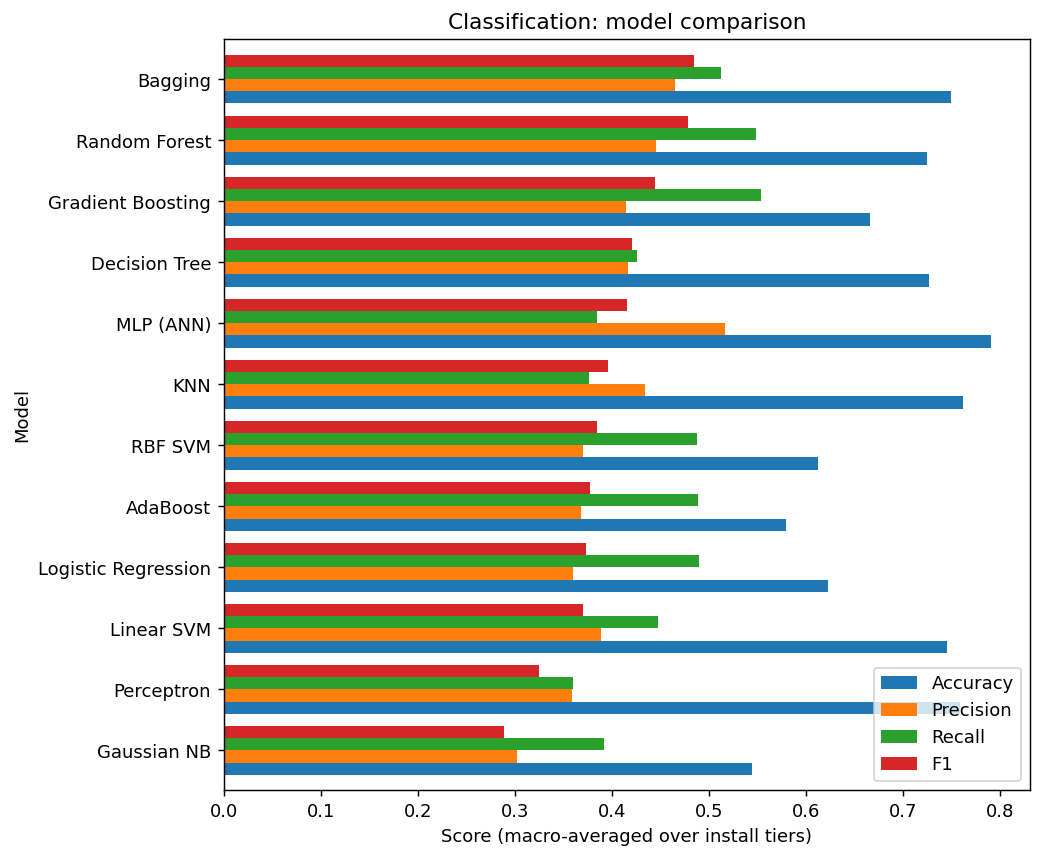

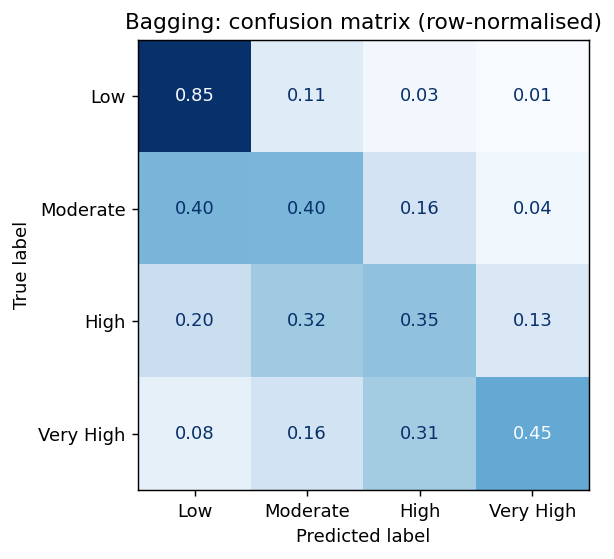

Best model: Bagging - per-tier scores on its 462,589 test apps


,Precision,Recall,F1,Support
Low,0.903,0.853,0.877,359145
Moderate,0.350,0.398,0.372,66402
High,0.277,0.351,0.310,27453
Very High,0.329,0.449,0.380,9589


In [ ]:
report('clf')

**6 · Regression models.** Tunes and trains the 13 regressors on `log(1 + Maximum Installs)`, using the same tier-stratified split and subsamples as the classifiers.

In [ ]:
REG = [
    S('Linear Regression', LinearRegression(n_jobs=-1)),
    S('Ridge', Ridge(random_state=SEED), {'alpha': [0.1, 1, 10, 100, 1000]}),
    S('Lasso', Lasso(selection='random', max_iter=2000, random_state=SEED), {'alpha': [1e-4, 1e-3, 1e-2, 1e-1]}),
    S('Bayesian Ridge', BayesianRidge()),
    S('KNN', KNeighborsRegressor(n_jobs=-1), {'n_neighbors': [5, 15, 31, 61], 'weights': ['uniform', 'distance']}, 'knn'),
    S('Linear SVR', LinearSVR(epsilon=0.5, loss='squared_epsilon_insensitive', dual=False, max_iter=2000, random_state=SEED), {'C': [0.01, 0.1, 1]}),
    S('RBF SVR', SVR(epsilon=0.5, cache_size=2000), {'C': [1, 10, 100]}, 'svm'),
    S('Decision Tree', DecisionTreeRegressor(random_state=SEED), {'max_depth': [8, 12, 16, 20, None], 'min_samples_leaf': [1, 20, 100]}),
    S('Random Forest', RandomForestRegressor(n_estimators=100, max_features='sqrt', min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
    S('AdaBoost', AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=100, learning_rate=0.5, random_state=SEED)),
    S('Gradient Boosting', HistGradientBoostingRegressor(max_iter=500, early_stopping=True, n_iter_no_change=20, random_state=SEED),
      {'learning_rate': [0.05, 0.1, 0.2], 'max_leaf_nodes': [31, 127]}),
    S('Bagging', BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=5), n_estimators=30, n_jobs=-1, random_state=SEED)),
    S('MLP (ANN)', MLPRegressor(hidden_layer_sizes=(128, 64), batch_size=1024, early_stopping=True, validation_fraction=.05, n_iter_no_change=4, max_iter=30, random_state=SEED)),
]
for s in REG: run('reg', *s)

Linear Regression    F1=0.3121  Acc=0.7695  Prec=0.4411  Rec=0.3018  (15s)
Ridge                F1=0.3296  Acc=0.7723  Prec=0.4707  Rec=0.3141  (1s)
Lasso                F1=0.3293  Acc=0.7724  Prec=0.4702  Rec=0.3139  (143s)
Bayesian Ridge       F1=0.3296  Acc=0.7723  Prec=0.4706  Rec=0.3141  (15s)
KNN                  F1=0.3388  Acc=0.7802  Prec=0.5629  Rec=0.3264  (0s)
Linear SVR           F1=0.3290  Acc=0.7723  Prec=0.4697  Rec=0.3138  (7s)
RBF SVR              F1=0.3547  Acc=0.7771  Prec=0.5298  Rec=0.3364  (259s)
Decision Tree        F1=0.3545  Acc=0.7764  Prec=0.5250  Rec=0.3371  (54s)
Random Forest        F1=0.3586  Acc=0.7922  Prec=0.6091  Rec=0.3433  (878s)
AdaBoost             F1=0.3008  Acc=0.7533  Prec=0.3494  Rec=0.3082  (1867s)
Gradient Boosting    F1=0.3981  Acc=0.7868  Prec=0.5775  Rec=0.3681  (553s)
Bagging              F1=0.4241  Acc=0.7941  Prec=0.5890  Rec=0.3907  (2033s)
MLP (ANN)            F1=0.3925  Acc=0.7845  Prec=0.5539  Rec=0.3629  (495s)


**7 · Regression results.** Same layout as the classification results; accuracy, precision, recall and F1 are computed on the 4 install tiers, alongside R², RMSE and MAE in log space.

Model,Train rows,Fit (s),Scored on,Accuracy,Precision,Recall,F1,F1 (common 50k),R2,RMSE,MAE
Bagging,"1,850,355",2033,full test,0.7941,0.5890,0.3907,0.4241,0.4216,0.5196,2.1888,1.7013
Gradient Boosting,"1,850,355",553,full test,0.7868,0.5775,0.3681,0.3981,0.3958,0.4943,2.2458,1.7815
MLP (ANN),"1,850,355",495,full test,0.7845,0.5539,0.3629,0.3925,0.3929,0.4767,2.2845,1.8096
Random Forest,"1,850,355",878,full test,0.7922,0.6091,0.3433,0.3586,0.3562,0.5154,2.1984,1.7352
RBF SVR,"50,000",259,50k subset,0.7771,0.5298,0.3364,0.3547,0.3547,0.4122,2.4160,1.9226
Decision Tree,"1,850,355",54,full test,0.7764,0.5250,0.3371,0.3545,0.3521,0.4171,2.4111,1.9168
KNN,"200,000",0,50k subset,0.7802,0.5629,0.3264,0.3388,0.3388,0.4172,2.4058,1.8944
Ridge,"1,850,355",1,full test,0.7723,0.4707,0.3141,0.3296,0.3299,0.3309,2.5833,2.0777
Bayesian Ridge,"1,850,355",15,full test,0.7723,0.4706,0.3141,0.3296,0.3299,0.3309,2.5833,2.0777
Lasso,"1,850,355",143,full test,0.7724,0.4702,0.3139,0.3293,0.3298,0.3309,2.5834,2.0779


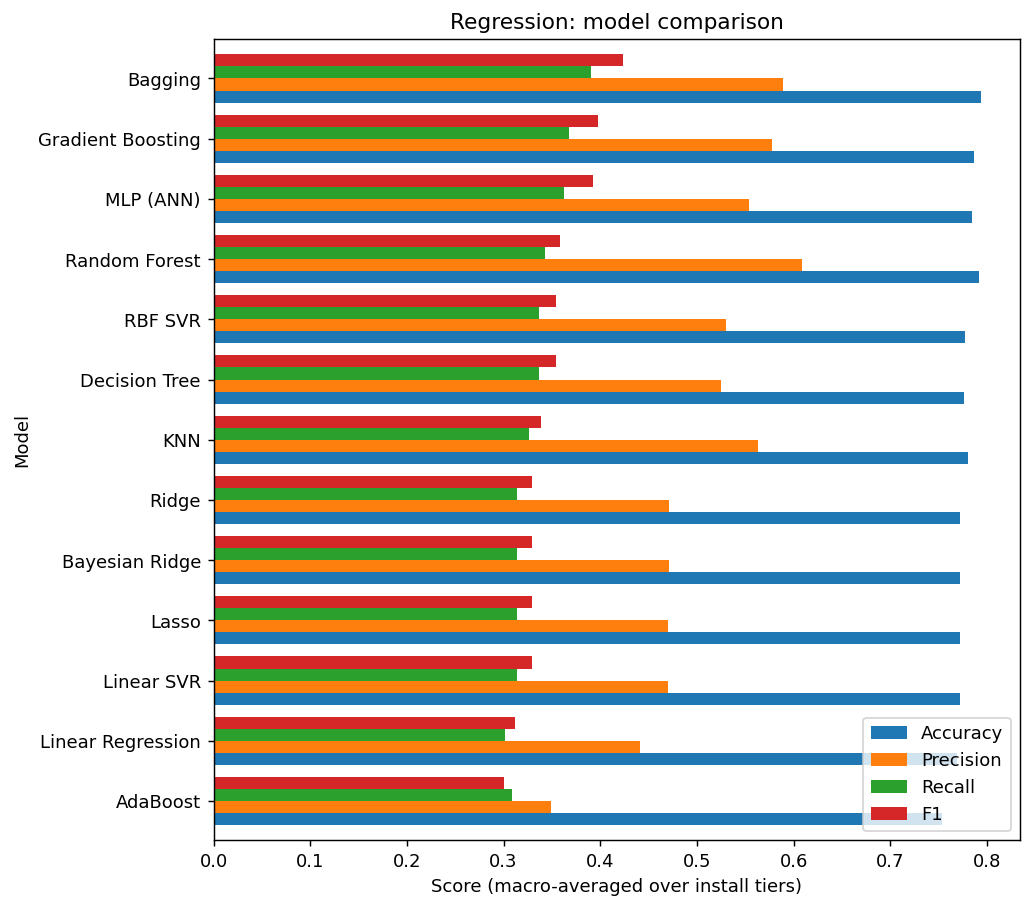

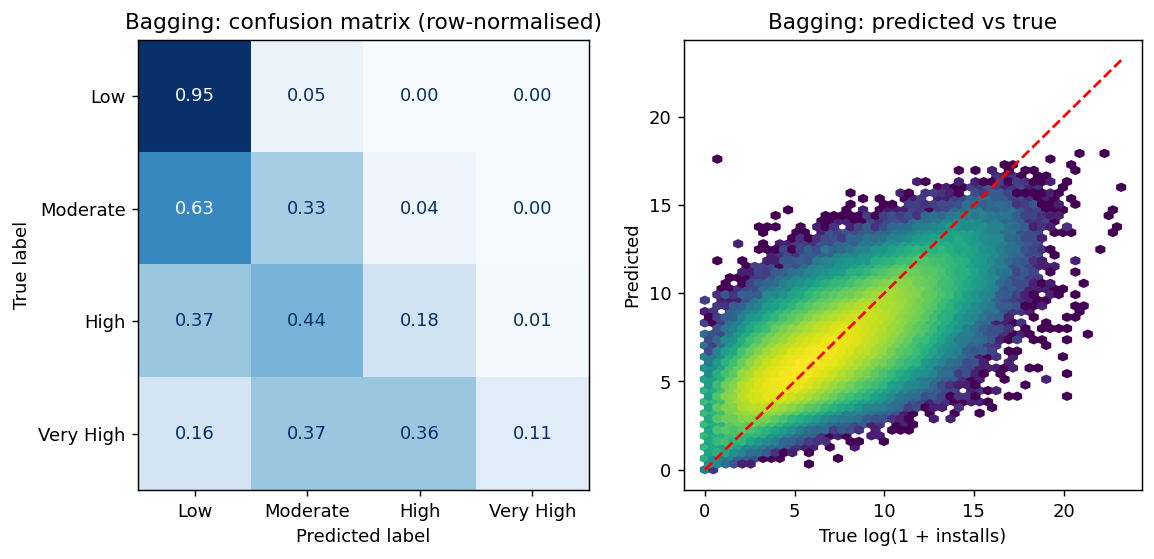

Best model: Bagging - per-tier scores on its 462,589 test apps


,Precision,Recall,F1,Support
Low,0.864,0.945,0.903,359145
Moderate,0.391,0.329,0.357,66402
High,0.397,0.180,0.247,27453
Very High,0.704,0.109,0.188,9589


In [ ]:
report('reg')

**8 · Final comparison table.** One table with every model of both tasks (best per task in bold) and a LaTeX version for the ACM report.

In [ ]:
FINAL = pd.DataFrame(RESULTS).assign(Task=lambda d: d.Task.map({'clf': 'Classification', 'reg': 'Regression'}))
FINAL = FINAL.sort_values(['Task', 'F1 (common 50k)'], ascending=[True, False]).reset_index(drop=True)[['Task', 'Model', 'Scored on', 'Accuracy', 'Precision', 'Recall', 'F1', 'F1 (common 50k)', 'R2', 'RMSE', 'MAE', 'Train rows', 'Fit (s)']]
top = FINAL.groupby('Task')['F1 (common 50k)'].idxmax().values
display(FINAL.style.format({'Train rows': '{:,.0f}', 'Fit (s)': '{:.0f}'}, precision=4, na_rep='–').hide(axis='index')
        .apply(lambda r: ['font-weight:bold;background-color:#d9ead3' if r.name in top else ''] * len(r), axis=1))
print(FINAL.drop(columns=['Train rows', 'Fit (s)']).to_latex(index=False, float_format='%.4f', na_rep='--', caption='Test performance of all models (macro-averaged over install tiers).', label='tab:results'))

Task,Model,Scored on,Accuracy,Precision,Recall,F1,F1 (common 50k),R2,RMSE,MAE,Train rows,Fit (s)
Classification,Bagging,full test,0.7494,0.4647,0.5127,0.4847,0.4848,–,–,–,"1,850,355",2195
Classification,Random Forest,full test,0.7247,0.4459,0.5488,0.4784,0.4801,–,–,–,"1,850,355",913
Classification,Gradient Boosting,full test,0.6660,0.4148,0.5540,0.4445,0.4443,–,–,–,"1,850,355",1213
Classification,Decision Tree,full test,0.7266,0.4166,0.4260,0.4211,0.4181,–,–,–,"1,850,355",105
Classification,MLP (ANN),full test,0.7912,0.5170,0.3847,0.4154,0.4156,–,–,–,"1,850,355",392
Classification,KNN,50k subset,0.7614,0.4337,0.3760,0.3960,0.3960,–,–,–,"200,000",0
Classification,RBF SVM,50k subset,0.6121,0.3701,0.4874,0.3851,0.3851,–,–,–,"50,000",583
Classification,AdaBoost,full test,0.5798,0.3678,0.4883,0.3776,0.3800,–,–,–,"1,850,355",1814
Classification,Logistic Regression,full test,0.6231,0.3601,0.4901,0.3734,0.3733,–,–,–,"1,850,355",173
Classification,Linear SVM,full test,0.7450,0.3887,0.4480,0.3698,0.3690,–,–,–,"1,850,355",135


\begin{table}
\caption{Test performance of all models (macro-averaged over install tiers).}
\label{tab:results}
\begin{tabular}{lllrrrrrrrr}
\toprule
Task & Model & Scored on & Accuracy & Precision & Recall & F1 & F1 (common 50k) & R2 & RMSE & MAE \\
\midrule
Classification & Bagging & full test & 0.7494 & 0.4647 & 0.5127 & 0.4847 & 0.4848 & -- & -- & -- \\
Classification & Random Forest & full test & 0.7247 & 0.4459 & 0.5488 & 0.4784 & 0.4801 & -- & -- & -- \\
Classification & Gradient Boosting & full test & 0.6660 & 0.4148 & 0.5540 & 0.4445 & 0.4443 & -- & -- & -- \\
Classification & Decision Tree & full test & 0.7266 & 0.4166 & 0.4260 & 0.4211 & 0.4181 & -- & -- & -- \\
Classification & MLP (ANN) & full test & 0.7912 & 0.5170 & 0.3847 & 0.4154 & 0.4156 & -- & -- & -- \\
Classification & KNN & 50k subset & 0.7614 & 0.4337 & 0.3760 & 0.3960 & 0.3960 & -- & -- & -- \\
Classification & RBF SVM & 50k subset & 0.6121 & 0.3701 & 0.4874 & 0.3851 & 0.3851 & -- & -- & -- \\
Classification & A

**9 · Selected hyperparameters.** The grid-search winner and its cross-validated score for every model, for the experimental-setup section of the report.

In [ ]:
display(pd.DataFrame(TUNING).assign(Task=lambda d: d.Task.map({'clf': 'Classification', 'reg': 'Regression'})).style
        .format(precision=4, na_rep='–').hide(axis='index'))

Task,Model,Selected hyperparameters,CV macro-F1,CV RMSE
Classification,Logistic Regression,C=0.1,0.3745,–
Classification,Perceptron,"alpha=1e-05, penalty=l1",0.3516,–
Classification,KNN,"n_neighbors=5, weights=distance",0.3868,–
Classification,Gaussian NB,var_smoothing=0.001,0.2976,–
Classification,Linear SVM,C=0.1,0.3685,–
Classification,RBF SVM,C=1,0.3676,–
Classification,Decision Tree,"criterion=gini, max_depth=None, min_samples_leaf=1",0.3748,–
Classification,Random Forest,fixed (not tuned),–,–
Classification,AdaBoost,fixed (not tuned),–,–
Classification,Gradient Boosting,"learning_rate=0.1, max_leaf_nodes=127",0.4296,–
